# Análisis exploratorio de datos y distribuciones

El análisis exploratorio de datos (EDA) es el primer paso antes de transformar los datos o construir un modelo. Consiste en resumir, visualizar y conocer a fondo las características del conjunto de datos para responder preguntas como: ¿qué tipo de datos son?, ¿son suficientes para el objetivo?, ¿hay valores faltantes o atípicos?, ¿cómo se distribuye cada variable?, ¿qué relaciones hay entre las variables y con la respuesta? {cite}`james2021,kuhn2013`

Este capítulo usa un inventario sintético de deslizamientos con seis variables y una respuesta binaria.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams['figure.dpi'] = 100

def inventario(n=1500, semilla=0):
    r = np.random.default_rng(semilla)
    elev = r.uniform(800, 3200, n)
    pend = np.clip(r.gamma(4, 5, n) + 0.004 * (elev - 800), 0, 70)
    curv = r.normal(0, 1, n)                                      # negativa: cóncava
    dist = r.exponential(300, n)
    lluv = 1500 + 0.5 * elev + r.normal(0, 300, n)
    lito = r.choice(['granito', 'esquisto', 'lutita'], n, p=[0.4, 0.35, 0.25])
    efecto_lito = pd.Series(lito).map({'granito': 0.0, 'esquisto': 0.8, 'lutita': 1.2}).values
    eta = -7 + 0.13 * pend - 0.5 * curv - 0.003 * dist + 0.0008 * lluv + efecto_lito
    y = (r.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
    return pd.DataFrame({'elevacion': elev, 'pendiente': pend, 'curvatura': curv, 'dist_cauce': dist,
                         'lluvia': lluv, 'litologia': lito, 'deslizamiento': y})

df = inventario()
print(df.head().round(2))
print(df.describe().round(2))
print(df['litologia'].value_counts())

   elevacion  pendiente  curvatura  dist_cauce   lluvia litologia  \
0    2328.71      27.44       0.45      554.67  2585.02   granito   
1    1447.49      18.93      -0.38       15.64  2341.58    lutita   
2     898.34      16.30      -1.69      133.37  1822.78  esquisto   
3     839.67      15.74      -1.81      261.33  1788.02   granito   
4    2751.85      21.42      -0.97       64.19  3019.25  esquisto   

   deslizamiento  
0              0  
1              0  
2              0  
3              0  
4              0  
       elevacion  pendiente  curvatura  dist_cauce   lluvia  deslizamiento
count    1500.00    1500.00    1500.00     1500.00  1500.00         1500.0
mean     2020.59      24.80       0.01      284.18  2520.46            0.2
std       694.93      10.57       0.99      293.75   462.79            0.4
min       800.46       4.07      -2.91        0.10  1177.99            0.0
25%      1427.80      17.19      -0.66       75.14  2188.24            0.0
50%      2046.56     

## Análisis univariado

El análisis univariado describe cada variable por separado. Las medidas de tendencia central (media, mediana, moda) y de dispersión (desviación estándar, rango intercuartílico) se complementan con la forma de la distribución: la asimetría y la curtosis. El histograma muestra la distribución de frecuencias; en un histograma de densidad el área de cada barra es la frecuencia relativa del intervalo y el área total es 1. El diagrama de caja resume los cuartiles y los atípicos, y el gráfico QQ compara los cuantiles de los datos con los de una distribución teórica, normalmente la normal: si los puntos se alejan de la recta, sobre todo en los extremos, el supuesto de normalidad no se cumple.

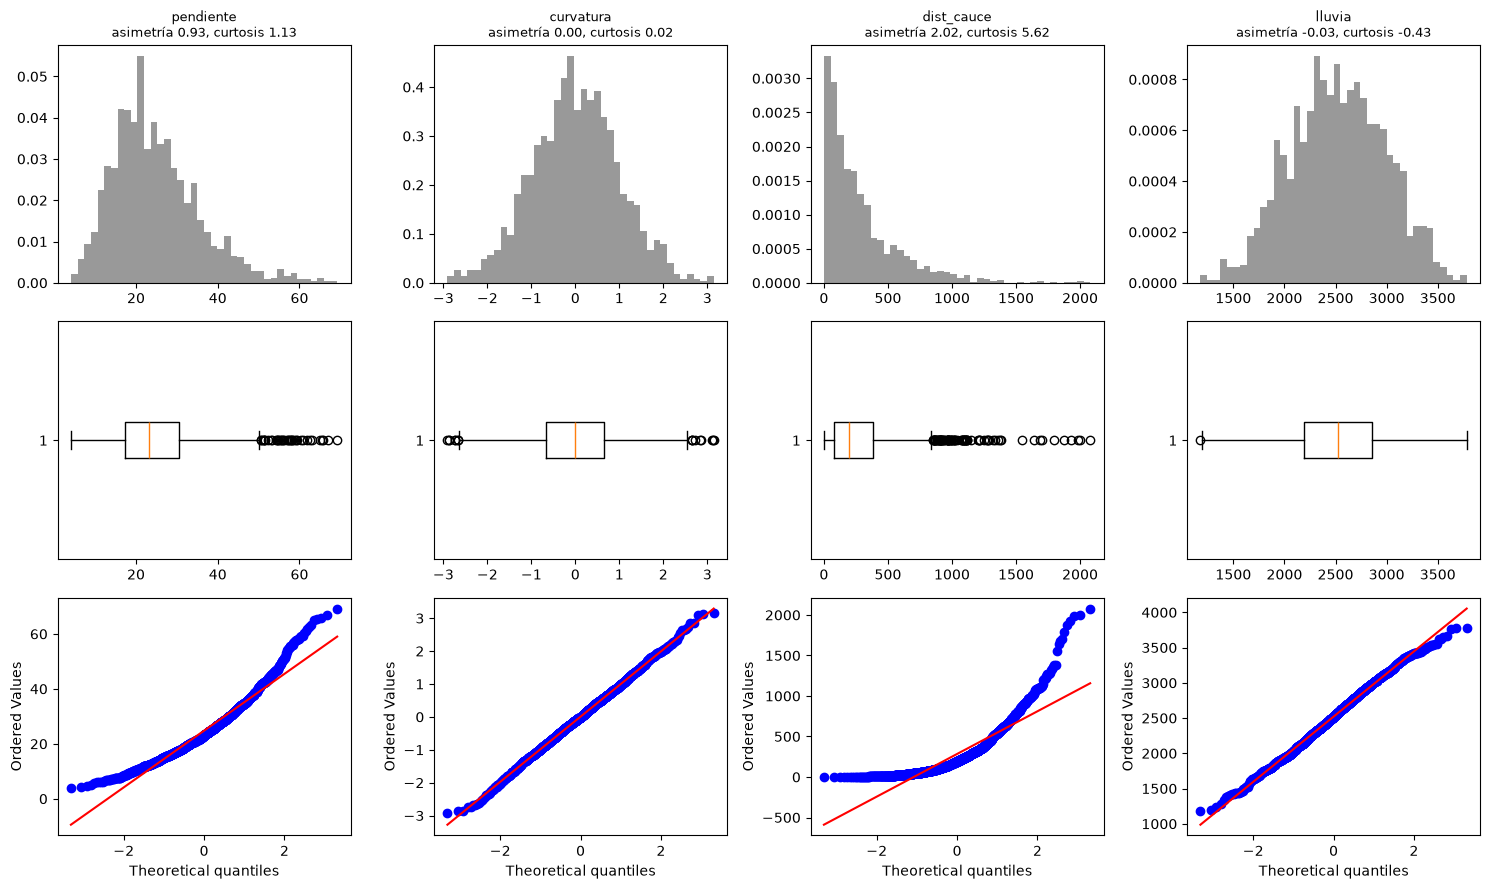

In [2]:
num = ['pendiente', 'curvatura', 'dist_cauce', 'lluvia']
fig, axs = plt.subplots(3, 4, figsize=(15, 9))
for j, v in enumerate(num):
    x = df[v]
    axs[0, j].hist(x, bins=40, density=True, color='0.6')
    axs[0, j].set_title(f'{v}\nasimetría {stats.skew(x):.2f}, curtosis {stats.kurtosis(x):.2f}', fontsize=9)
    axs[1, j].boxplot(x, orientation='horizontal')
    stats.probplot(x, dist='norm', plot=axs[2, j]); axs[2, j].set_title('')
plt.tight_layout(); plt.show()

La distancia a los cauces es muy asimétrica, con una cola larga a la derecha, y su gráfico QQ se curva; la curvatura y la lluvia se acercan a la normal. Esto anticipa que la distancia se beneficiará de una transformación logarítmica.

## Distribuciones de probabilidad

Conocer la distribución de los datos ayuda a elegir el modelo. La función de masa de probabilidad (PMF) da la probabilidad de cada valor de una variable discreta; la función de densidad (PDF) cumple el mismo papel para variables continuas, de modo que la probabilidad es el área bajo la curva en un intervalo; y la función de distribución acumulada (CDF) da la probabilidad de que la variable sea menor o igual que un valor. Algunas distribuciones frecuentes en geociencias son la binomial (número de éxitos en $n$ ensayos, como laderas que fallan entre $n$ inspeccionadas), la de Poisson (número de eventos en un intervalo, como sismos por año), la exponencial (tiempo entre eventos), la normal, la lognormal (tamaños de grano, concentraciones, áreas de deslizamientos), la gamma y la de Weibull (lluvias, velocidades de viento, tiempos de falla).

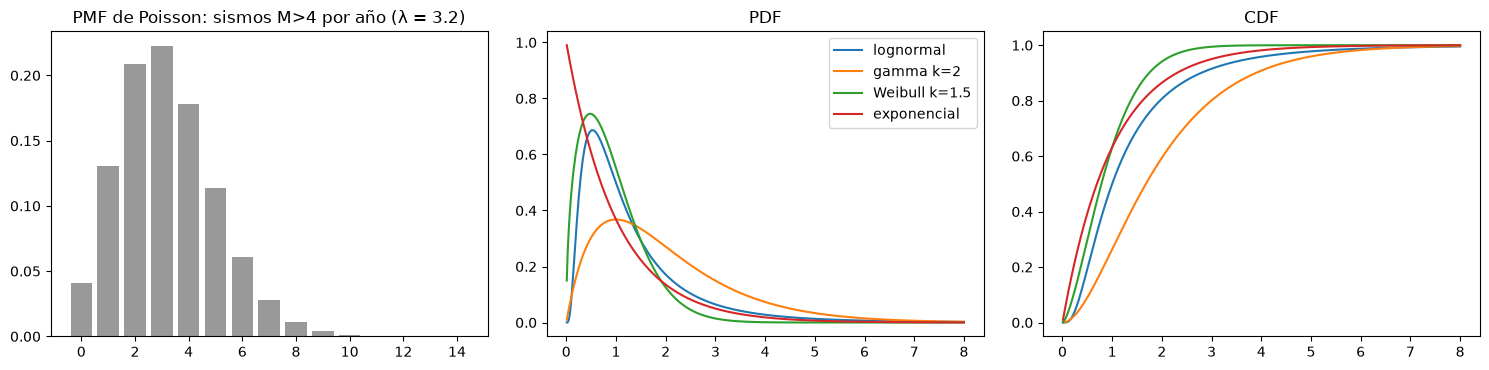

P(al menos 6 sismos en un año) = 0.105


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
k = np.arange(0, 15)
axs[0].bar(k, stats.poisson.pmf(k, 3.2), color='0.6'); axs[0].set_title('PMF de Poisson: sismos M>4 por año (λ = 3.2)')
x = np.linspace(0.01, 8, 400)
for nom, dist in [('lognormal', stats.lognorm(0.8)), ('gamma k=2', stats.gamma(2)), ('Weibull k=1.5', stats.weibull_min(1.5)), ('exponencial', stats.expon())]:
    axs[1].plot(x, dist.pdf(x), label=nom); axs[2].plot(x, dist.cdf(x), label=nom)
axs[1].set_title('PDF'); axs[2].set_title('CDF'); axs[1].legend()
plt.tight_layout(); plt.show()
print(f'P(al menos 6 sismos en un año) = {1 - stats.poisson.cdf(5, 3.2):.3f}')

## El teorema del límite central

Aunque una variable no tenga distribución normal, la media de muestras suficientemente grandes y tomadas de forma independiente sí tiende a distribuirse normalmente, con media igual a la poblacional y desviación estándar $\sigma/\sqrt{n}$. Este teorema es la base de los intervalos de confianza y de muchas pruebas estadísticas del capítulo siguiente. La celda siguiente lo comprueba con la distancia a los cauces, muy asimétrica.

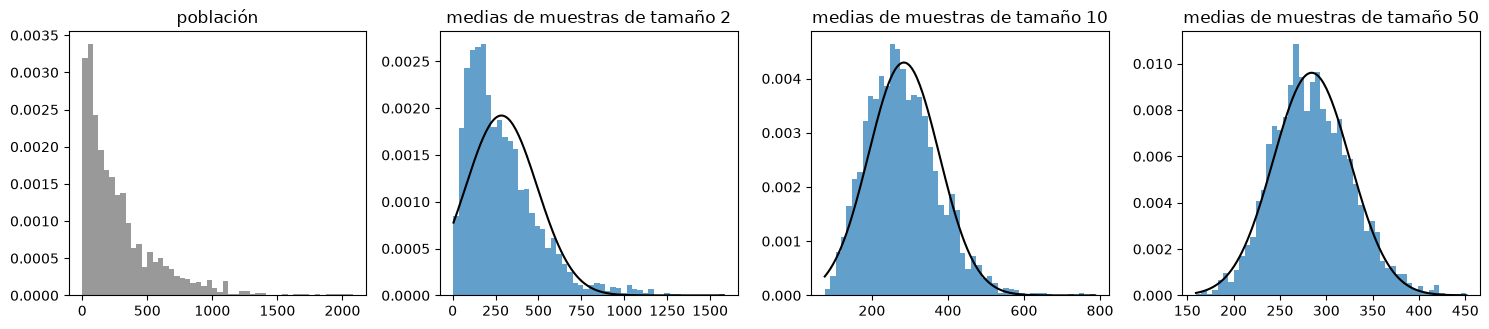

In [4]:
pobl = df['dist_cauce'].values
rng = np.random.default_rng(5)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
axs[0].hist(pobl, bins=50, density=True, color='0.6'); axs[0].set_title('población')
for a, m in zip(axs[1:], [2, 10, 50]):
    medias = rng.choice(pobl, (3000, m)).mean(axis=1)
    a.hist(medias, bins=50, density=True, color='tab:blue', alpha=0.7)
    xx = np.linspace(medias.min(), medias.max(), 200)
    a.plot(xx, stats.norm.pdf(xx, pobl.mean(), pobl.std() / np.sqrt(m)), 'k')
    a.set_title(f'medias de muestras de tamaño {m}')
plt.tight_layout(); plt.show()

## Análisis bivariado y correlación

El análisis bivariado estudia las relaciones entre pares de variables y entre cada variable y la respuesta. La covarianza mide qué tanto varían juntas dos variables, pero depende de sus unidades. El coeficiente de correlación de Pearson la normaliza entre -1 y 1 y mide la asociación lineal; el de Spearman, que trabaja con los rangos, mide la asociación monótona y es menos sensible a los atípicos. Una correlación alta entre dos predictores anticipa problemas de multicolinealidad en los modelos lineales (capítulo {doc}`12_RegresionLineal`). Recuerde que la correlación mide asociación, no causalidad.

Para una respuesta binaria, la comparación más útil es la de las distribuciones de cada predictor en los dos grupos, con y sin deslizamiento.

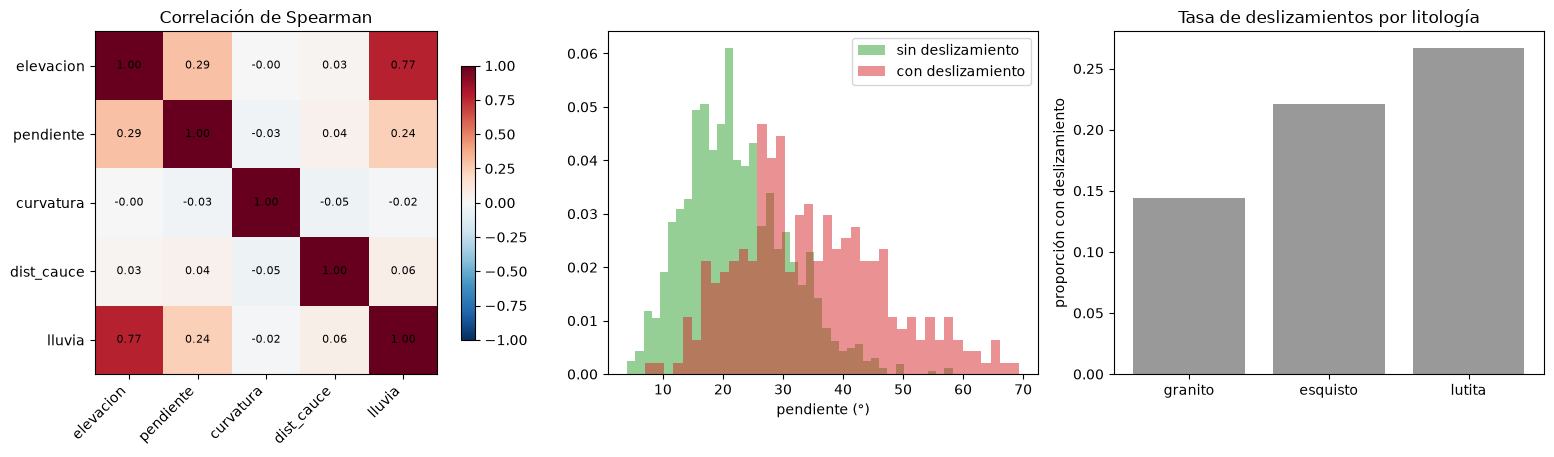

In [5]:
num_all = ['elevacion', 'pendiente', 'curvatura', 'dist_cauce', 'lluvia']
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.1, 1, 1]})
corr = df[num_all].corr(method='spearman')
h = axs[0].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axs[0].set_xticks(range(5)); axs[0].set_xticklabels(num_all, rotation=45, ha='right'); axs[0].set_yticks(range(5)); axs[0].set_yticklabels(num_all)
for i in range(5):
    for j in range(5):
        axs[0].text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
axs[0].set_title('Correlación de Spearman'); fig.colorbar(h, ax=axs[0], shrink=0.8)
for g, col in [(0, 'tab:green'), (1, 'tab:red')]:
    axs[1].hist(df.loc[df.deslizamiento == g, 'pendiente'], bins=40, density=True, alpha=0.5, color=col, label=['sin deslizamiento', 'con deslizamiento'][g])
axs[1].set_xlabel('pendiente (°)'); axs[1].legend()
tasa = df.groupby('litologia')['deslizamiento'].mean().sort_values()
axs[2].bar(tasa.index, tasa.values, color='0.6'); axs[2].set_ylabel('proporción con deslizamiento'); axs[2].set_title('Tasa de deslizamientos por litología')
plt.tight_layout(); plt.show()

La elevación, la pendiente y la lluvia están correlacionadas entre sí, como en el ejemplo de confusión del capítulo 1. Los deslizamientos ocurren en pendientes mayores, y las lutitas y los esquistos tienen tasas más altas que el granito. Todo esto orienta la selección de variables y la elección del modelo.

## Para profundizar

El capítulo 2 de {cite}`wasserman2004` resume las distribuciones de probabilidad, y el capítulo 3 de {cite}`kuhn2013` trata la exploración y la transformación de predictores. Los notebooks 05 del curso (EDA y estadística) amplían estos temas con datos reales.